# 15 — Observation Operators: Gaps, Interpolation, Averaging Kernels, and Fusion

Every notebook so far observed the state itself, with gaps. Real
instruments do not: they sample between grid points, they smooth the
state through a retrieval, they come in several kinds with different
footprints and error levels. The observation operator $H$ is where
that reality enters the likelihood, and this notebook walks through the
four operators vardax ships — [`MaskedIdentity`](xref:api#vardax.MaskedIdentity),
[`LinearObs`](xref:api#vardax.LinearObs),
[`InterpObs`](xref:api#vardax.InterpObs),
[`AveragingKernel`](xref:api#vardax.AveragingKernel) — and their composition in
[`MultiInstrumentFusion`](xref:api#vardax.MultiInstrumentFusion), on a static,
linear-Gaussian problem where everything has a closed form. Chapter
[11](../11_observation_operators.md) is the reference.

## The linear-Gaussian analysis, with $H$ in the spotlight

With a Gaussian prior $x \sim \mathcal{N}(x_b, B)$ and a linear
observation $y = Hx + \varepsilon$, $\varepsilon \sim \mathcal{N}(0, R)$,
the posterior is Gaussian with

$$
x^* = x_b + K\,(y - H x_b), \qquad K = B H^{\top}\big(H B H^{\top} + R\big)^{-1},
$$

$$
P^* = (I - KH)\,B = \big(B^{-1} + H^{\top} R^{-1} H\big)^{-1}.
$$

This is the BLUE of chapter [4](../04_oi_blue.md), computed by
[`OptimalInterpolation`](xref:api#vardax.OptimalInterpolation); the two forms of $P^*$ are
equal by the Woodbury identity. Read the pieces with $H$ in mind:

- $H$ maps the state to *what the instrument would measure* if the
  state were true. It is the forward model of the instrument.
- $H^{\top}$ maps a data-space vector back to the state: it *spreads*
  an innovation onto the state variables the observation depends on.
  The gain $K = B H^{\top}(\cdot)^{-1}$ then lets $B$ spread it further,
  to variables correlated with those.
- The precision form of $P^*$ says information adds: every instrument
  contributes $H_i^{\top} R_i^{-1} H_i$, and independent instruments
  simply sum. That is the whole theory of multi-instrument fusion, and
  the reason it needs no common grid.
- $\mathrm{tr}(KH)$, the *degrees of freedom for signal*, counts how
  many independent directions in state space the observations
  determine. It is at most the number of observations and usually much
  less, because $R$ and the smoothness in $B$ both discount them.

Every operator below must also satisfy the adjoint identity
$\langle H u, v \rangle = \langle u, H^{\top} v \rangle$, which vardax
checks in its test suite and which we check here for the sparse
interpolation operator: an operator whose transpose is wrong gives a
gradient that is wrong, and a 4DVar that walks in the wrong direction.

## The averaging kernel

A satellite retrieval of a profile $x$ (a column of methane mixing
ratios, say) is not a noisy copy of $x$. The retrieval algorithm
solves its own inverse problem with its own prior $x_a$, and reports
a smoothed mixture of the atmosphere and that prior (Rodgers 2000).
vardax's `AveragingKernel` writes the reported quantity as

$$
\hat y = A\,\big(h \odot x + (1 - h) \odot x_a\big) + \varepsilon ,
$$

where the kernel $A$ smooths across levels and the weighting vector
$h$ says, level by level, what fraction of the signal comes from the
atmosphere ($h_i \to 1$ where the instrument is sensitive) and what
fraction is the retrieval prior filling in ($h_i \to 0$ where it is
not). This is the form of total-column products, where $h$ is a
pressure weighting; $h = 1$ gives a pure smoothing $A x$. Its
tangent-linear is $A\,\mathrm{diag}(h)$, and
$\mathrm{tr}(A\,\mathrm{diag}(h))$ is the retrieval's degrees of
freedom. Treating $\hat y$ as a direct measurement of $x$ — skipping
the kernel — attributes the smoothing and the prior contamination to
the atmosphere, and biases the analysis toward $x_a$ wherever $h$ is
small. Section 4 measures that bias.

In [1]:
import jax

# A smooth prior with precise data gives obs-space systems whose conjugate
# gradient solves stall in single precision; this notebook runs in float64.
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp  # noqa: E402
import lineax as lx  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from vardax import (  # noqa: E402
    AveragingKernel,
    Batch1D,
    InstrumentRegistry,
    InstrumentSpec,
    LaplaceCovariance,
    LinearObs,
    MaskedIdentity,
    MultiInstrumentFusion,
    OptimalInterpolation,
    ThreeDVar,
    interp_obs_from_coords,
)

## 1. A correlated field and its prior

The state is a $24 \times 32$ field with a squared-exponential prior
covariance of correlation length $\ell$ — a Gaussian random field. The
truth is one draw from the prior and the background is the prior mean
(zero), so the analysis is exactly Gaussian-process regression and
every posterior quantity has a closed form we can check the library
against. The state is carried as a flat vector of $N = 768$ values
(the operators reshape as they need), and the prior covariance is a
dense `lineax.MatrixLinearOperator` — fine at this size, and the place
a structured `gaussx` operator (Kronecker, Toeplitz, Matérn) would go
at scale so that its inverse and square root stay matrix-free.

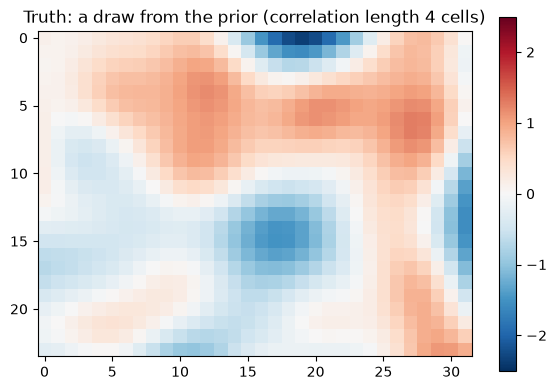

In [2]:
NY, NX = 24, 32
ELL, SIGMA_FIELD = 4.0, 1.0
y_axis, x_axis = np.arange(NY, dtype=float), np.arange(NX, dtype=float)
YY, XX = np.meshgrid(y_axis, x_axis, indexing="ij")
coords = np.stack([YY.ravel(), XX.ravel()], axis=1)
d2 = ((coords[:, None, :] - coords[None, :, :]) ** 2).sum(-1)
N = NY * NX
NUGGET = 1e-6  # keeps B numerically positive definite
B_np = SIGMA_FIELD**2 * np.exp(-0.5 * d2 / ELL**2) + NUGGET * np.eye(N)
B_dense = jnp.asarray(B_np, dtype=jnp.float64)
B_op = lx.TaggedLinearOperator(lx.MatrixLinearOperator(B_dense), lx.positive_semidefinite_tag)


def diag_cov(variance, n):
    return lx.TaggedLinearOperator(lx.DiagonalLinearOperator(jnp.full(n, variance)), lx.positive_semidefinite_tag)


def make_oi(obs_op, R_op):
    # The obs-space system H B H^T + R has condition number in the thousands
    # for a smooth prior and precise data, so the inner CG needs room.
    return OptimalInterpolation(
        obs_op=obs_op, prior_mean=x_b, prior_cov_op=B_op, obs_cov_op=R_op,
        cg_rtol=1e-5, cg_max_steps=3000,
    )


rng = np.random.default_rng(0)
x_true = jnp.asarray(np.linalg.cholesky(B_np) @ rng.standard_normal(N), dtype=jnp.float64)
x_b = jnp.zeros(N)


def posterior_dense(H_dense, R_diag):
    """Closed-form posterior covariance for a dense H and diagonal R."""
    HB = H_dense @ B_dense
    S = HB @ H_dense.T + jnp.diag(R_diag)
    return B_dense - HB.T @ jnp.linalg.solve(S, HB)


def dfs(H_dense, R_diag):
    """Degrees of freedom for signal, tr(KH)."""
    HB = H_dense @ B_dense
    S = HB @ H_dense.T + jnp.diag(R_diag)
    return float(jnp.trace(jnp.linalg.solve(S, HB @ H_dense.T)))


def as_grid(v):
    return np.asarray(v).reshape(NY, NX)


fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(as_grid(x_true), cmap="RdBu_r", vmin=-2.5, vmax=2.5)
plt.colorbar(im, ax=ax)
ax.set_title(f"Truth: a draw from the prior (correlation length {ELL:.0f} cells)")
plt.tight_layout()
plt.show()

## 2. Gaps: masked identity and its selection-matrix twin

The simplest instrument reads the state at 30 % of the grid points.
There are two ways to say so. `MaskedIdentity` keeps the data on the
state's grid and carries the gap pattern as a mask that is applied at
call time; `LinearObs` with a $n_{obs} \times N$ selection matrix
keeps only the observed values. They describe the same likelihood and
give the same analysis — the library treats the mask as part of the
operator, on both sides of $R^{-1}$, exactly so that this holds. The
difference is practical: masks are natural for gridded products with
gaps (SST under clouds, along-track altimetry), selection matrices for
point data, and the latter never allocate the missing entries.

observed fraction 0.32; n_obs = 243
RMSE background 0.656, analysis 0.131
max |masked-identity analysis - selection-matrix analysis| = 1.25e-06


degrees of freedom for signal: 61.6 of 243 observations


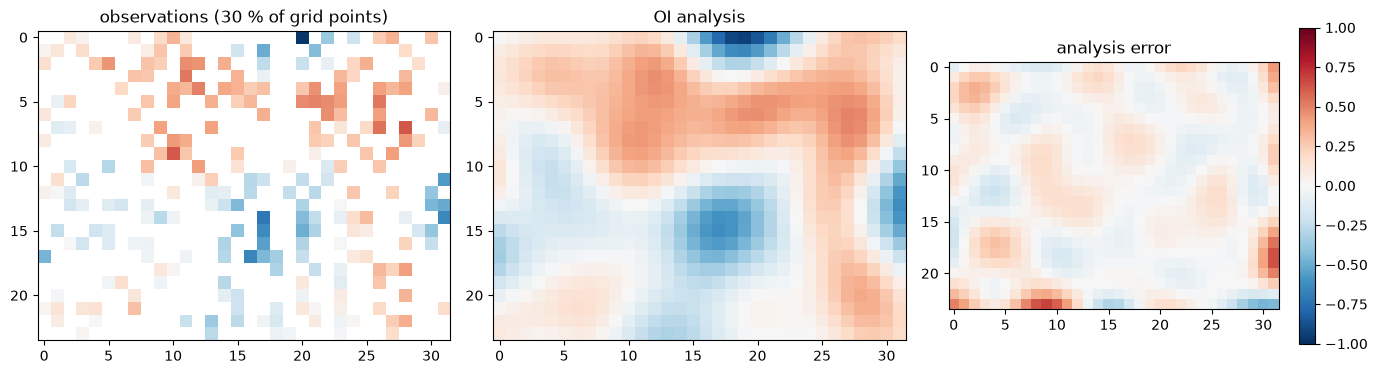

In [3]:
k_mask, k_noise = jax.random.split(jax.random.PRNGKey(1))
SIGMA_POINT = 0.2
mask = (jax.random.uniform(k_mask, (N,)) < 0.3).astype(jnp.float64)
noise = SIGMA_POINT * jax.random.normal(k_noise, (N,))
y_grid = (x_true + noise) * mask

oi_masked = make_oi(MaskedIdentity(), diag_cov(SIGMA_POINT**2, N))
x_masked = oi_masked(Batch1D(input=y_grid[None], mask=mask[None]))[0]

idx_obs = jnp.flatnonzero(mask)
n_sel = idx_obs.shape[0]
S_dense = jnp.zeros((n_sel, N)).at[jnp.arange(n_sel), idx_obs].set(1.0)
S_op = lx.FunctionLinearOperator(lambda v: v[idx_obs], jax.ShapeDtypeStruct((N,), jnp.float64))
oi_select = make_oi(LinearObs(operator=S_op), diag_cov(SIGMA_POINT**2, n_sel))
y_points = (x_true + noise)[idx_obs]
x_select = oi_select(Batch1D(input=y_points[None], mask=jnp.ones((1, n_sel))))[0]

print(f"observed fraction {float(mask.mean()):.2f}; n_obs = {n_sel}")
print(f"RMSE background {float(jnp.sqrt(jnp.mean((x_b - x_true) ** 2))):.3f}, analysis {float(jnp.sqrt(jnp.mean((x_masked - x_true) ** 2))):.3f}")
print(f"max |masked-identity analysis - selection-matrix analysis| = {float(jnp.max(jnp.abs(x_masked - x_select))):.2e}")
print(f"degrees of freedom for signal: {dfs(S_dense, jnp.full(n_sel, SIGMA_POINT**2)):.1f} of {n_sel} observations")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].imshow(as_grid(jnp.where(mask == 1, y_grid, jnp.nan)), cmap="RdBu_r", vmin=-2.5, vmax=2.5)
axes[0].set_title("observations (30 % of grid points)")
axes[1].imshow(as_grid(x_masked), cmap="RdBu_r", vmin=-2.5, vmax=2.5)
axes[1].set_title("OI analysis")
im = axes[2].imshow(as_grid(x_masked - x_true), cmap="RdBu_r", vmin=-1, vmax=1)
axes[2].set_title("analysis error")
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()

The degrees of freedom for signal are well below the observation count:
with a correlation length of four cells, neighbouring observations
largely repeat each other, and the prior already "knows" the field is
smooth. That is the information-theoretic reason dense sampling of a
smooth field has diminishing returns.

## 3. Off-grid observations: sparse bilinear interpolation

Point measurements rarely fall on grid nodes. `InterpObs` holds a
precomputed four-point bilinear stencil for each observation, so $H$
is a sparse $n_{obs} \times N$ matrix that is never formed, and
$H^{\top}$ — the scatter of each innovation back onto its four
surrounding nodes — comes from `jax.vjp` of the same code. We build
it from coordinates, verify the adjoint identity, run the analysis,
and map the posterior standard deviation: small near observations,
recovering to the prior value $\sigma$ a few correlation lengths away.
The covariance here is the closed form $B - BH^{\top}(HBH^{\top}+R)^{-1}HB$;
the lazy `LaplaceCovariance` adapter of notebook
[14](14_posterior_uncertainty_L63.ipynb) builds the same operator by
conjugate gradients on $B^{-1} + H^{\top}R^{-1}H$, which is the right
tool once $B$ is a structured `gaussx` operator with a closed-form
inverse, and the wrong one for a dense, nearly singular $B$ like this
one. Section 4 uses the adapter where it belongs.

adjoint test: <Hu, v> = 3.83324, <u, H^T v> = 3.83324


RMSE analysis 0.130; DFS 57.8 of 120


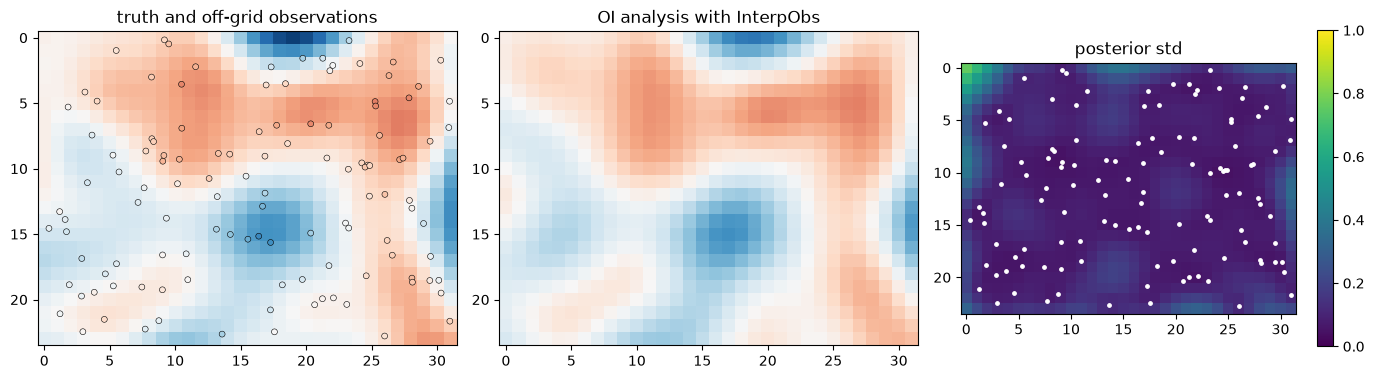

In [4]:
N_PTS, SIGMA_PT = 120, 0.1
k_pts, k_pn = jax.random.split(jax.random.PRNGKey(2))
pts = jax.random.uniform(k_pts, (N_PTS, 2), minval=jnp.array([0.0, 0.0]), maxval=jnp.array([NY - 1.0, NX - 1.0]))
interp = interp_obs_from_coords((y_axis, x_axis), np.asarray(pts))
y_pts = interp(x_true) + SIGMA_PT * jax.random.normal(k_pn, (N_PTS,))

# Adjoint test <Hu, v> = <u, H^T v>
H_lin = interp.linearize(x_true)
u = jax.random.normal(jax.random.PRNGKey(3), (N,))
v = jax.random.normal(jax.random.PRNGKey(4), (N_PTS,))
print(f"adjoint test: <Hu, v> = {float(jnp.sum(H_lin.mv(u) * v)):.5f}, <u, H^T v> = {float(jnp.sum(u * H_lin.transpose().mv(v))):.5f}")

oi_interp = make_oi(interp, diag_cov(SIGMA_PT**2, N_PTS))
x_interp = oi_interp(Batch1D(input=y_pts[None], mask=jnp.ones((1, N_PTS))))[0]

H_interp_dense = jax.jacfwd(interp)(x_true)  # (N_PTS, N): dense only for the closed-form check
P_interp = posterior_dense(H_interp_dense, jnp.full(N_PTS, SIGMA_PT**2))
std_interp = jnp.sqrt(jnp.diag(P_interp))
print(f"RMSE analysis {float(jnp.sqrt(jnp.mean((x_interp - x_true) ** 2))):.3f}; DFS {dfs(H_interp_dense, jnp.full(N_PTS, SIGMA_PT**2)):.1f} of {N_PTS}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].imshow(as_grid(x_true), cmap="RdBu_r", vmin=-2.5, vmax=2.5)
axes[0].scatter(pts[:, 1], pts[:, 0], c=y_pts, cmap="RdBu_r", vmin=-2.5, vmax=2.5, s=18, edgecolors="black", linewidths=0.4)
axes[0].set_title("truth and off-grid observations")
axes[1].imshow(as_grid(x_interp), cmap="RdBu_r", vmin=-2.5, vmax=2.5)
axes[1].set_title("OI analysis with InterpObs")
im = axes[2].imshow(as_grid(std_interp), cmap="viridis", vmin=0, vmax=SIGMA_FIELD)
axes[2].scatter(pts[:, 1], pts[:, 0], s=6, color="white")
axes[2].set_title("posterior std")
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()

## 4. Averaging kernels: why skipping them biases the analysis

A one-dimensional profile problem, 20 levels. The instrument's kernel
$A$ is a row-normalised Gaussian smoother, its sensitivity $h$ is near
one at the lowest levels and decays aloft, so the retrieval sees the
lower levels well and reports mostly its own prior at the top, with a
few degrees of freedom in total; that retrieval prior $x_a$ is a
climatology that differs from our background $x_b$. We compare two analyses over many
noise realisations:

- **naive**: `MaskedIdentity`, i.e. pretend $\hat y$ is a noisy copy of
  $x$;
- **kernel-aware**: `AveragingKernel`, i.e. the correct likelihood.

Averaging the error over realisations isolates the *bias*: the part of
the error that does not go away with more data. The kernel-aware
analysis also knows what it cannot know — its posterior standard
deviation stays at the prior value where $A$ is weak.

degrees of freedom of the retrieval, tr(A diag(h)) = 2.30 (of 20 levels)


profile RMSE over realisations and levels: naive 1.491, kernel-aware 0.746, background 0.979


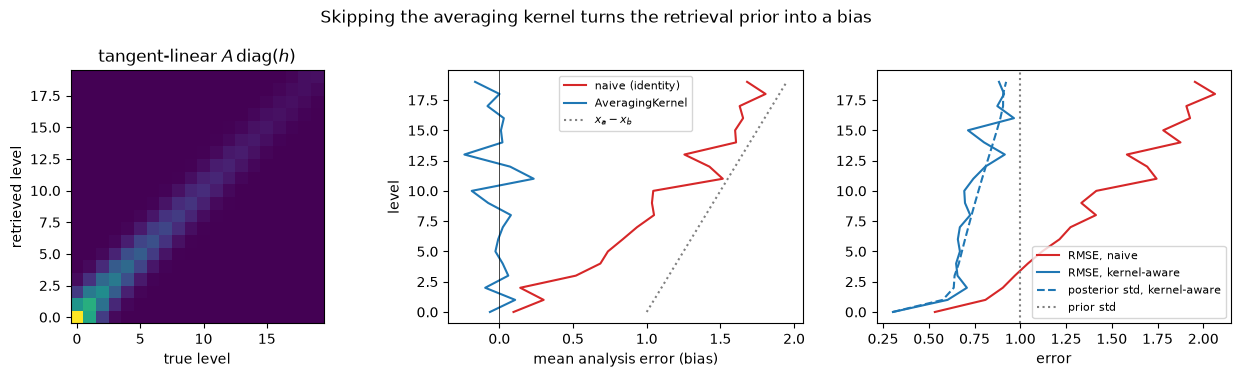

In [5]:
N_LEV = 20
levels = jnp.arange(N_LEV, dtype=jnp.float64)
# Row-normalised smoother, and a sensitivity that is strong low and weak aloft.
G = jnp.exp(-0.5 * ((levels[:, None] - levels[None, :]) / 1.2) ** 2)
A_mat = G / G.sum(axis=1, keepdims=True)
h_sens = jnp.exp(-levels / 6.0)
print(f"degrees of freedom of the retrieval, tr(A diag(h)) = {float(jnp.trace(A_mat * h_sens[None, :])):.2f} (of {N_LEV} levels)")

x_a = 1.0 + 0.05 * levels  # retrieval prior: a climatology
x_b_prof = jnp.zeros(N_LEV)  # our background
SIGMA_PROF_B, SIGMA_RET = 1.0, 0.05
B_prof = diag_cov(SIGMA_PROF_B**2, N_LEV)
R_prof = diag_cov(SIGMA_RET**2, N_LEV)
ak = AveragingKernel(kernel_matrix=lx.MatrixLinearOperator(A_mat), prior_profile=x_a, pressure_weights=h_sens)

model_naive = ThreeDVar(obs_op=MaskedIdentity(), prior_mean=x_b_prof, prior_cov_op=B_prof, obs_cov_op=R_prof)
model_ak = ThreeDVar(obs_op=ak, prior_mean=x_b_prof, prior_cov_op=B_prof, obs_cov_op=R_prof)

N_REAL = 64
k_t, k_r = jax.random.split(jax.random.PRNGKey(5))
x_true_prof = x_b_prof + SIGMA_PROF_B * jax.random.normal(k_t, (N_REAL, N_LEV))
y_ret = jax.vmap(ak)(x_true_prof) + SIGMA_RET * jax.random.normal(k_r, (N_REAL, N_LEV))
batch_prof = Batch1D(input=y_ret, mask=jnp.ones_like(y_ret))
xa_naive = model_naive(batch_prof)
xa_ak = model_ak(batch_prof)

bias_naive = jnp.mean(xa_naive - x_true_prof, axis=0)
bias_ak = jnp.mean(xa_ak - x_true_prof, axis=0)
rmse_naive = jnp.sqrt(jnp.mean((xa_naive - x_true_prof) ** 2, axis=0))
rmse_ak = jnp.sqrt(jnp.mean((xa_ak - x_true_prof) ** 2, axis=0))
post_ak = LaplaceCovariance(prior_cov_op=B_prof, obs_cov_op=R_prof)(xa_ak[0], model_ak, batch=None)
std_ak = jnp.sqrt(jnp.stack([post_ak.cov.mv(jnp.eye(N_LEV)[i])[i] for i in range(N_LEV)]))

print(f"profile RMSE over realisations and levels: naive {float(jnp.sqrt(jnp.mean((xa_naive - x_true_prof) ** 2))):.3f}, "
      f"kernel-aware {float(jnp.sqrt(jnp.mean((xa_ak - x_true_prof) ** 2))):.3f}, background {float(jnp.sqrt(jnp.mean(x_true_prof**2))):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].imshow(A_mat * h_sens[None, :], cmap="viridis", origin="lower")
axes[0].set_xlabel("true level")
axes[0].set_ylabel("retrieved level")
axes[0].set_title("tangent-linear $A\\,\\mathrm{diag}(h)$")
axes[1].plot(bias_naive, levels, color="tab:red", label="naive (identity)")
axes[1].plot(bias_ak, levels, color="tab:blue", label="AveragingKernel")
axes[1].plot(x_a - x_b_prof, levels, color="gray", linestyle=":", label="$x_a - x_b$")
axes[1].axvline(0, color="black", lw=0.5)
axes[1].set_xlabel("mean analysis error (bias)")
axes[1].set_ylabel("level")
axes[1].legend(fontsize=8)
axes[2].plot(rmse_naive, levels, color="tab:red", label="RMSE, naive")
axes[2].plot(rmse_ak, levels, color="tab:blue", label="RMSE, kernel-aware")
axes[2].plot(std_ak, levels, color="tab:blue", linestyle="--", label="posterior std, kernel-aware")
axes[2].axvline(SIGMA_PROF_B, color="gray", linestyle=":", label="prior std")
axes[2].set_xlabel("error")
axes[2].legend(fontsize=8)
fig.suptitle("Skipping the averaging kernel turns the retrieval prior into a bias")
plt.tight_layout()
plt.show()

The naive analysis is biased toward $x_a - x_b$ where $h$ is small: it
reads the retrieval's prior as atmospheric signal, and the higher the
level the more of the reported value is prior. The kernel-aware analysis is unbiased, its RMSE
tracks its own posterior standard deviation (a calibrated analysis,
in the sense of notebook [14](14_posterior_uncertainty_L63.ipynb)), and
both rise to the prior value aloft, where the instrument has no
sensitivity and honesty means saying so.

## 5. Two instruments, one likelihood

Back on the 2-D field: a wide-footprint imager that averages
$4 \times 4$ blocks with modest noise, and a handful of precise in-situ
points off-grid. Each is an `InstrumentSpec` with its own operator,
mask and $R$; `MultiInstrumentFusion` composes them at the likelihood
level, and `to_observation_operator()` flattens the per-instrument
outputs (in sorted instrument-id order) into the single-vector form the
analysis classes expect, with a block-diagonal $R$ to match. The
posterior precision of the fused analysis is the sum of the
instruments' contributions; we verify that identity numerically and
look at what each instrument buys.

per-instrument predictions: {'imager': (48,), 'insitu': (16,)}


imager only  : RMSE 0.236, mean posterior std 0.200, DFS 38.7
in-situ only : RMSE 0.402, mean posterior std 0.578, DFS 15.8


fused        : RMSE 0.195, mean posterior std 0.167, DFS 44.3
relative error of the precision-addition identity: 2.7e-09


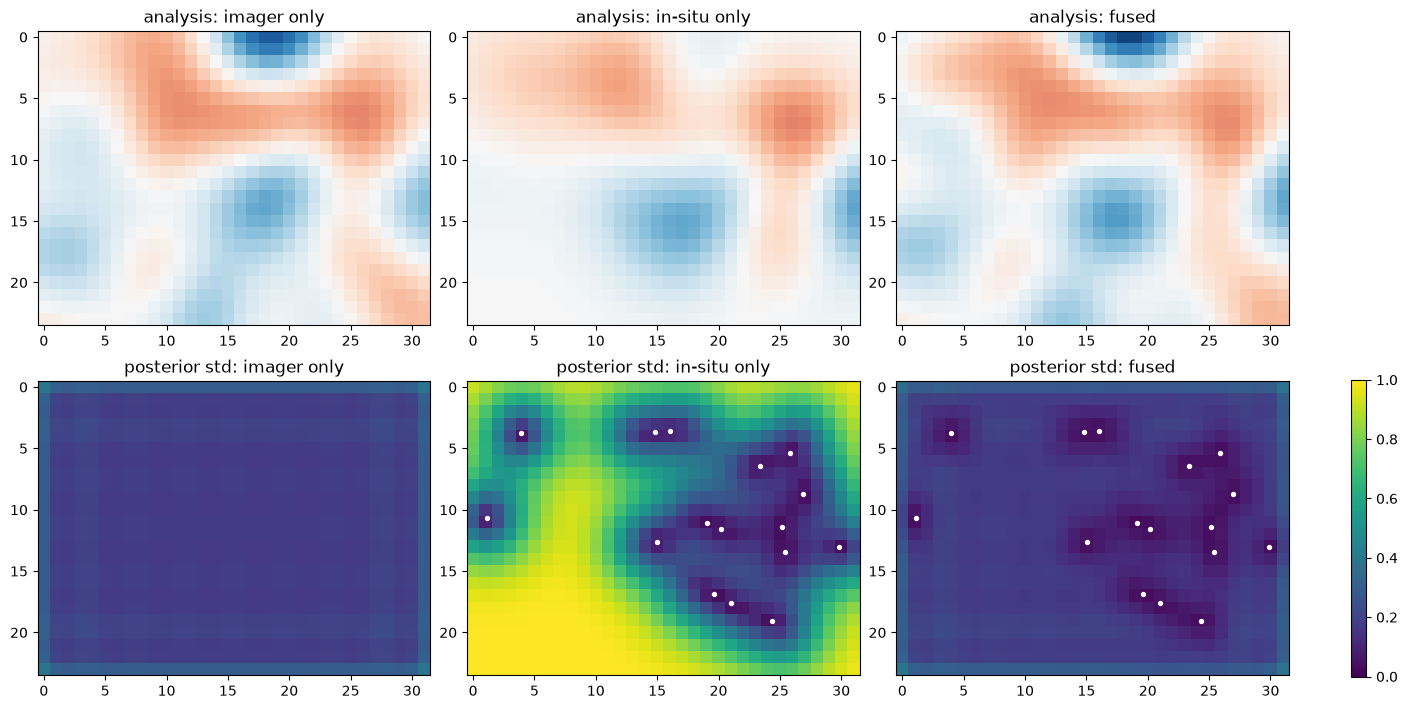

In [6]:
BLOCK = 4
n_by, n_bx = NY // BLOCK, NX // BLOCK
SIGMA_IMG, SIGMA_INSITU, N_INSITU = 0.15, 0.03, 16


def block_average(x):
    return x.reshape(n_by, BLOCK, n_bx, BLOCK).mean(axis=(1, 3)).ravel()


imager = LinearObs(operator=lx.FunctionLinearOperator(block_average, jax.ShapeDtypeStruct((N,), jnp.float64)))
k_is, k_in, k_im = jax.random.split(jax.random.PRNGKey(6), 3)
pts_insitu = jax.random.uniform(k_is, (N_INSITU, 2), minval=jnp.array([0.0, 0.0]), maxval=jnp.array([NY - 1.0, NX - 1.0]))
insitu = interp_obs_from_coords((y_axis, x_axis), np.asarray(pts_insitu))

y_img = imager(x_true) + SIGMA_IMG * jax.random.normal(k_im, (n_by * n_bx,))
y_insitu = insitu(x_true) + SIGMA_INSITU * jax.random.normal(k_in, (N_INSITU,))

registry = InstrumentRegistry(entries={
    "imager": InstrumentSpec(obs_op=imager, mask=jnp.ones(n_by * n_bx), obs_cov_op=diag_cov(SIGMA_IMG**2, n_by * n_bx), instrument_id="imager"),
    "insitu": InstrumentSpec(obs_op=insitu, mask=jnp.ones(N_INSITU), obs_cov_op=diag_cov(SIGMA_INSITU**2, N_INSITU), instrument_id="insitu"),
})
fusion = MultiInstrumentFusion(registry=registry)
fused_op = fusion.to_observation_operator()
per_instrument = fusion(x_true)
print("per-instrument predictions:", {k: v.shape for k, v in per_instrument.items()})

# Flattened order is sorted by instrument id: "imager" then "insitu".
y_fused = jnp.concatenate([y_img, y_insitu])
R_fused_diag = jnp.concatenate([jnp.full(n_by * n_bx, SIGMA_IMG**2), jnp.full(N_INSITU, SIGMA_INSITU**2)])
R_fused = lx.TaggedLinearOperator(lx.DiagonalLinearOperator(R_fused_diag), lx.positive_semidefinite_tag)


def analyse(obs_op, y, R_diag):
    oi = make_oi(obs_op, lx.TaggedLinearOperator(lx.DiagonalLinearOperator(R_diag), lx.positive_semidefinite_tag))
    xa = oi(Batch1D(input=y[None], mask=jnp.ones((1, y.shape[0]))))[0]
    H_dense = jax.jacfwd(obs_op)(x_true)
    return xa, posterior_dense(H_dense, R_diag), H_dense


results = {
    "imager only": analyse(imager, y_img, jnp.full(n_by * n_bx, SIGMA_IMG**2)),
    "in-situ only": analyse(insitu, y_insitu, jnp.full(N_INSITU, SIGMA_INSITU**2)),
    "fused": analyse(fused_op, y_fused, R_fused_diag),
}
R_diags = {"imager only": jnp.full(n_by * n_bx, SIGMA_IMG**2), "in-situ only": jnp.full(N_INSITU, SIGMA_INSITU**2), "fused": R_fused_diag}
for name, (xa, P, H) in results.items():
    print(f"{name:13s}: RMSE {float(jnp.sqrt(jnp.mean((xa - x_true) ** 2))):.3f}, mean posterior std {float(jnp.sqrt(jnp.diag(P)).mean()):.3f}, DFS {dfs(H, R_diags[name]):.1f}")

# Precision addition: P_fused^{-1} = B^{-1} + sum_i H_i^T R_i^{-1} H_i.
H_img, H_ins = (np.asarray(results[k][2], dtype=np.float64) for k in ("imager only", "in-situ only"))
prec_sum = np.linalg.inv(B_np) + H_img.T @ H_img / SIGMA_IMG**2 + H_ins.T @ H_ins / SIGMA_INSITU**2
H_all = np.vstack([H_img, H_ins])
HB_all = H_all @ B_np
P_fused64 = B_np - HB_all.T @ np.linalg.solve(HB_all @ H_all.T + np.diag(np.asarray(R_fused_diag, dtype=np.float64)), HB_all)
print(f"relative error of the precision-addition identity: {np.linalg.norm(np.linalg.inv(P_fused64) - prec_sum) / np.linalg.norm(prec_sum):.1e}")

fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for ax, (name, (xa, P, _)) in zip(axes[0], results.items()):
    ax.imshow(as_grid(xa), cmap="RdBu_r", vmin=-2.5, vmax=2.5)
    ax.set_title(f"analysis: {name}")
for ax, (name, (xa, P, _)) in zip(axes[1], results.items()):
    im = ax.imshow(as_grid(jnp.sqrt(jnp.diag(P))), cmap="viridis", vmin=0, vmax=SIGMA_FIELD)
    ax.set_title(f"posterior std: {name}")
axes[1][1].scatter(pts_insitu[:, 1], pts_insitu[:, 0], s=8, color="white")
axes[1][2].scatter(pts_insitu[:, 1], pts_insitu[:, 0], s=8, color="white")
fig.colorbar(im, ax=axes[1].tolist(), fraction=0.02)
plt.show()

The imager constrains the large scales everywhere but cannot see
within a footprint; the in-situ points are precise but local. Fused,
the posterior precision is exactly the sum of the two contributions —
the identity holds to floating-point accuracy — and the standard
deviation map shows both signatures at once: a uniformly lowered floor
from the imager, with deep wells at the in-situ sites. No regridding,
no common resolution, no averaging of one product onto the other's
grid; each instrument is compared with the state through its own $H$.

## Summary

- $H$ is the forward model of the instrument and $H^{\top}$ spreads
  innovations back onto the state; the analysis and its covariance
  follow from the BLUE, and the degrees of freedom for signal
  $\mathrm{tr}(KH)$ measure how much the data actually determine.
- Gaps can be a mask on the state grid or a selection matrix on the
  data; vardax treats them identically.
- Off-grid observations use a sparse interpolation stencil whose
  adjoint is derived automatically; the adjoint identity is the test
  that it is right.
- Retrievals are not measurements of the state. The averaging kernel
  belongs in $H$; leaving it out turns the retrieval prior into a bias
  concentrated where the instrument is least sensitive.
- Instruments fuse by adding precisions. `MultiInstrumentFusion` does
  that at the likelihood level, each instrument on its own footprint.

Chapter [17](../17_methane_example.md) applies the kernel and fusion
machinery to satellite methane, where they are the difference between
a usable inversion and a biased one.